# Integral against pulse height, channel by channel (-82 V, DCRC1pB trigger)

*Tenth notebook of `relcal`. Draft prepared with Claude Code for A. Villano, 2026-11-01.*

For each of the six channels, the `integral` of every real trigger against its **pulse height**: the largest sample above the baseline, `current_max` of `goldsluice`'s `peak` (with `amps_per_adc` = 1 it is in ADC counts, equal to `adc_max - baseline_mean`). No cut on the position. Both quantities use the same baseline, the mean of samples 10 to 500.

For a pulse of fixed shape the integral is proportional to the height. Saturation breaks that: once a channel reaches its saturated height, the height stops growing and only the integral does (the flat top gets longer), up to the integral of a pulse held at that height to the end of the trace. The dotted lines mark both: the saturated height (the 99.99th percentile of the height) and the largest integral it allows (that height times the 2.88 ms from the trigger to the end of the trace).

Needs `goldpan` and the output of `r76-82v-dcrc1pb.dataset.toml` in `~/goldsluice-output/r76-82v-dcrc1pb`. Run with the `darkmatter_cli_env` kernel.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import colors

from goldpan.adapters import parquet
from spots_82v import LETTERS, OUT

q = parquet.read(OUT, detector="NAI-S2").quantities
real = np.asarray(q["trigger_type"]).astype(str) == "Unknown"
I = {k: np.asarray(q[f"Side2p{k}"]["integral"], dtype=float)[real] for k in LETTERS}         # ADC counts x s
H = {k: np.asarray(q[f"Side2p{k}"]["current_max"], dtype=float)[real] for k in LETTERS}      # ADC counts above the baseline
T_AFTER = (4096 - 500) * 0.8e-6            # seconds from the trigger (sample 500) to the end of the trace
H_SAT = {k: np.percentile(H[k], 99.99) for k in LETTERS}

print(f"{real.sum():,} real triggers")
print(f"{'':28}" + "".join(f"{'Side2p' + k:>10}" for k in LETTERS))
print(f"{'saturated height (counts)':28}" + "".join(f"{H_SAT[k]:>10.0f}" for k in LETTERS))
print(f"{'its largest integral':28}" + "".join(f"{H_SAT[k] * T_AFTER:>10.2f}" for k in LETTERS))
print(f"{'height above 2000 (glitch?)':28}" + "".join(f"{(H[k] > 2000).sum():>10,}" for k in LETTERS))

1,436,655 real triggers
                               Side2pA   Side2pB   Side2pC   Side2pD   Side2pE   Side2pF
saturated height (counts)         1322      1105       598       938       688       897
its largest integral              3.80      3.18      1.72      2.70      1.98      2.58
height above 2000 (glitch?)         27        36        55         5         8        20


## All six channels

The density of events in the plane of height and integral, on a log colour scale, one panel per channel, all on the same axes. A few events have a height of thousands of counts (a single-sample spike far above any pulse, counted in the table above); they are outside the plotted range.

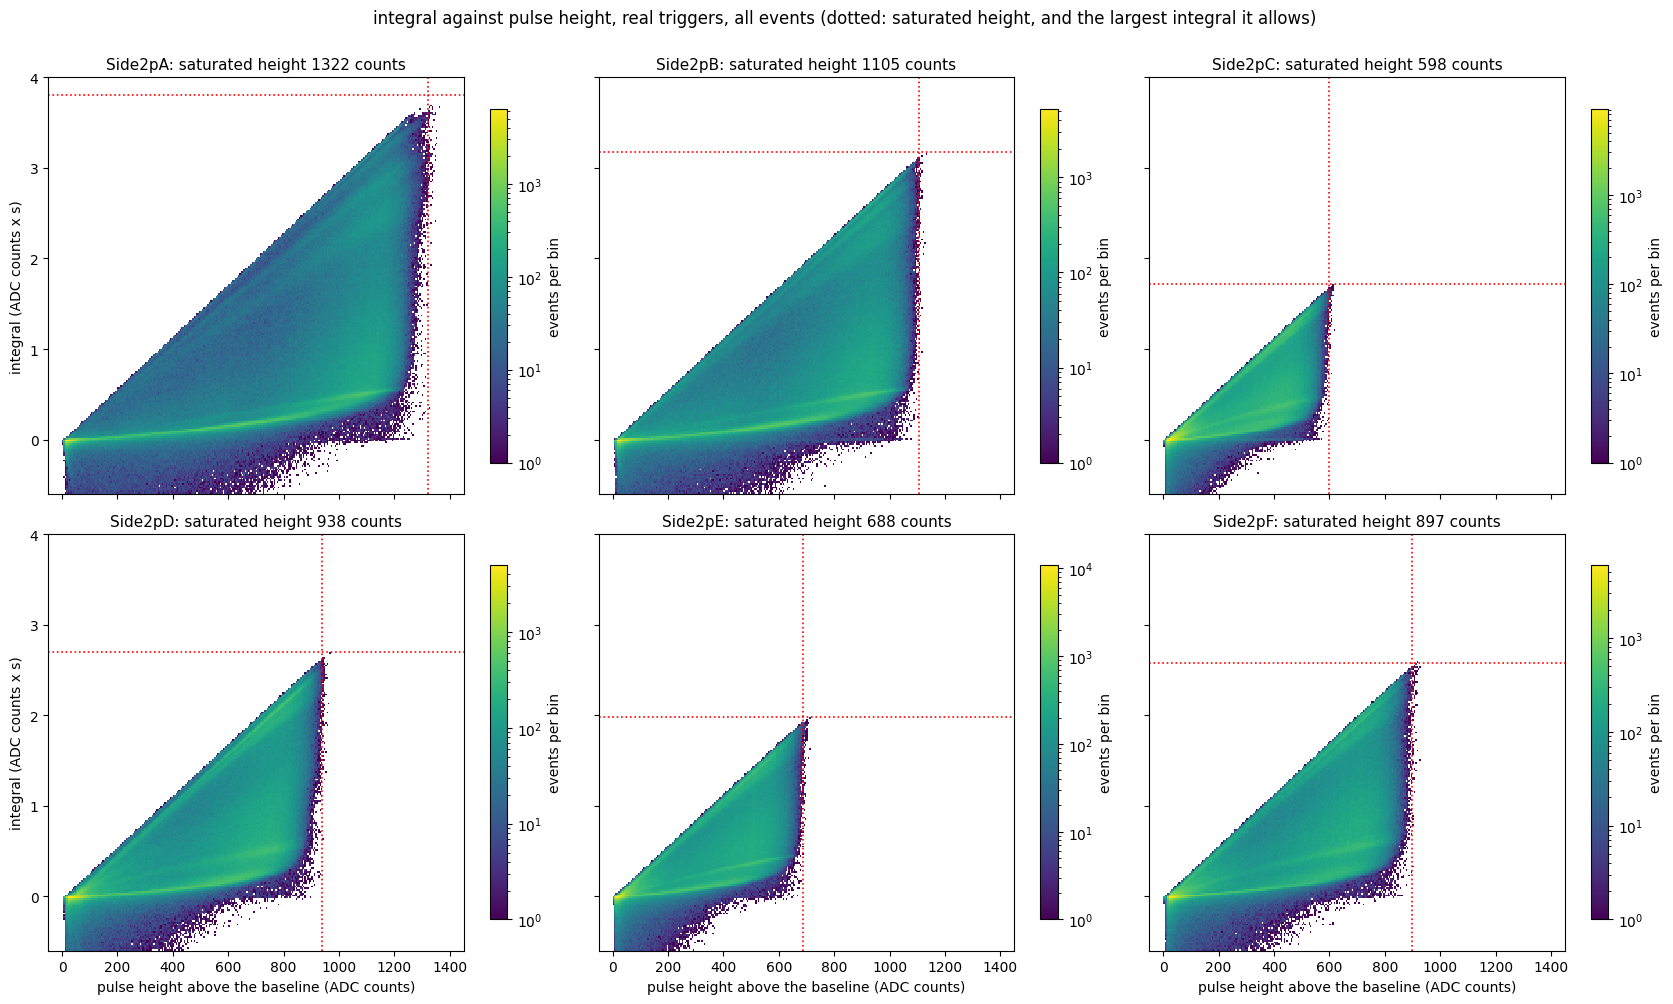

In [2]:
HR, IR = (-50, 1450), (-0.6, 4.0)
fig, axes = plt.subplots(2, 3, figsize=(17, 10), sharex=True, sharey=True)
for ax, k in zip(axes.flat, LETTERS):
    h = ax.hist2d(H[k], I[k], bins=[300, 230], range=[HR, IR], cmap="viridis", norm=colors.LogNorm(), cmin=1)
    ax.axvline(H_SAT[k], color="r", linestyle=":", linewidth=1.2)
    ax.axhline(H_SAT[k] * T_AFTER, color="r", linestyle=":", linewidth=1.2)
    ax.set_title(f"Side2p{k}: saturated height {H_SAT[k]:.0f} counts", fontsize=11)
    fig.colorbar(h[3], ax=ax, shrink=0.85, label="events per bin")
for ax in axes[-1]:
    ax.set_xlabel("pulse height above the baseline (ADC counts)")
for ax in axes[:, 0]:
    ax.set_ylabel("integral (ADC counts x s)")
fig.suptitle("integral against pulse height, real triggers, all events (dotted: saturated height, and the largest integral it allows)", y=1.0)
fig.tight_layout()
plt.show()

## Integral per unit height

The ratio `integral / height` is the effective length of the pulse (in seconds): constant for pulses of one shape, growing as the flat top of a saturated pulse lengthens. Plotted against the height, for events with a height above 50 counts (below that the ratio is mostly noise).

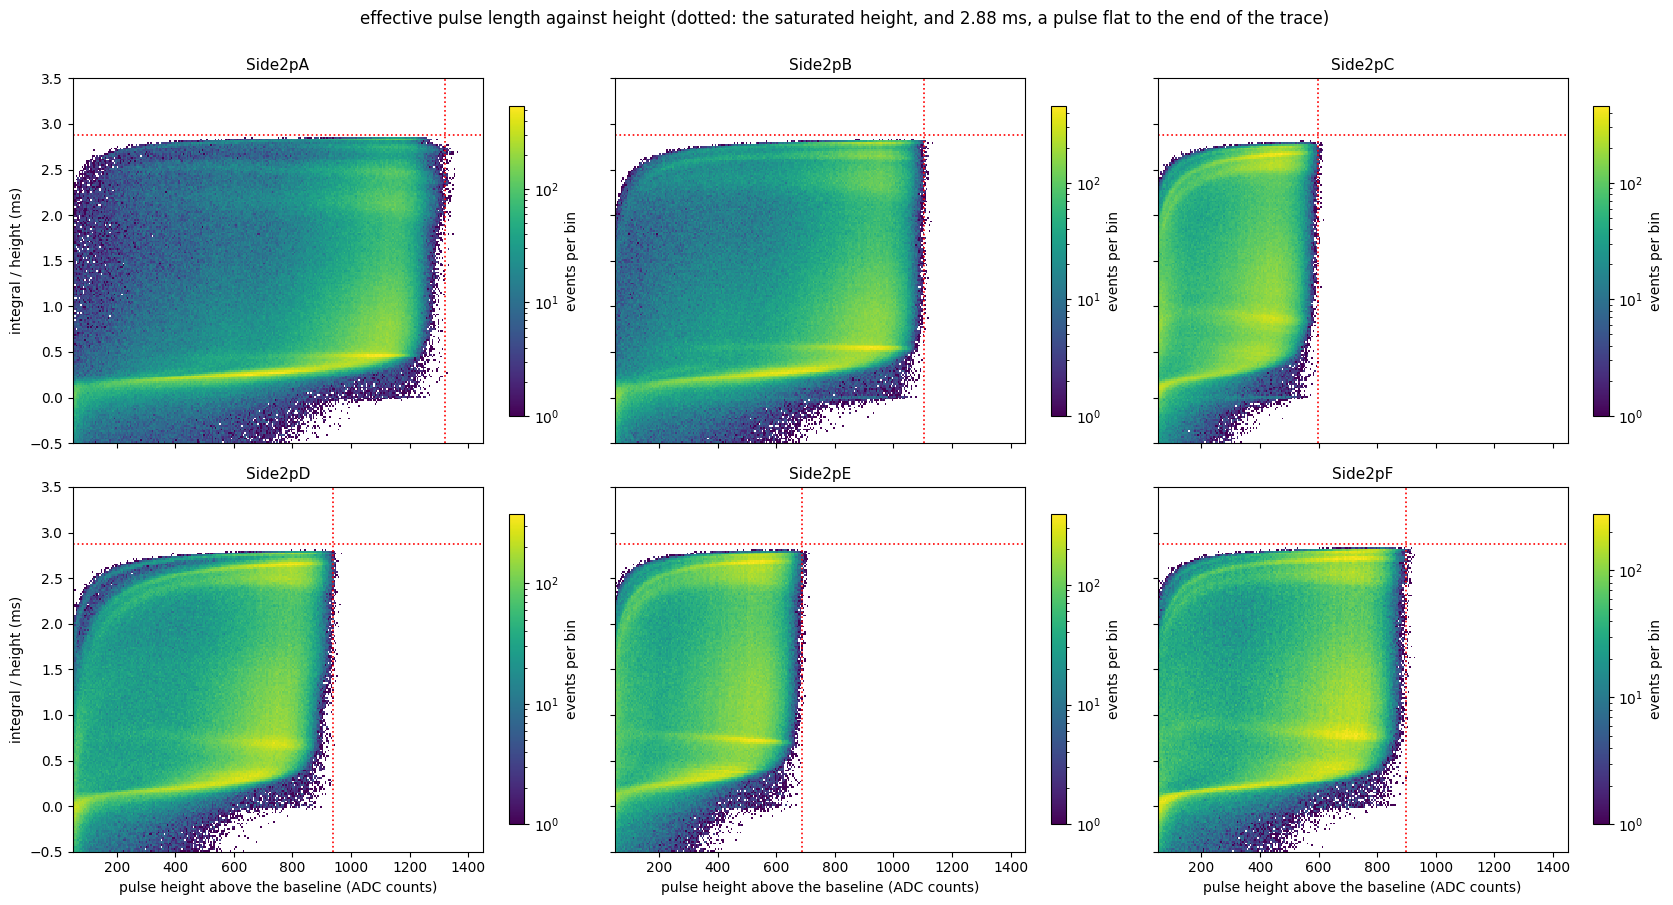

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharex=True, sharey=True)
for ax, k in zip(axes.flat, LETTERS):
    m = H[k] > 50
    h = ax.hist2d(H[k][m], I[k][m] / H[k][m] * 1e3, bins=[280, 200], range=[(50, 1450), (-0.5, 3.5)],
                  cmap="viridis", norm=colors.LogNorm(), cmin=1)
    ax.axvline(H_SAT[k], color="r", linestyle=":", linewidth=1.2)
    ax.axhline(T_AFTER * 1e3, color="r", linestyle=":", linewidth=1.2)
    ax.set_title(f"Side2p{k}", fontsize=11)
    fig.colorbar(h[3], ax=ax, shrink=0.85, label="events per bin")
for ax in axes[-1]:
    ax.set_xlabel("pulse height above the baseline (ADC counts)")
for ax in axes[:, 0]:
    ax.set_ylabel("integral / height (ms)")
fig.suptitle("effective pulse length against height (dotted: the saturated height, and 2.88 ms, a pulse flat to the end of the trace)", y=1.0)
fig.tight_layout()
plt.show()

**What to look for.** Where each channel leaves the straight line through the origin (the start of saturation), how far below the saturated height that happens, and whether the channels agree on it in units of their own saturated height. Events far off the main band (a large height with a small integral, or a negative integral) are pile-up, a pulse in the pretrigger window, or a glitch; `low-integral-traces.ipynb` shows how to draw a few of them.